In [ ]:
# Fruit Shop Sales Analysis with pandas
Sales of 7 fruits in two shops (Bitola and Ohrid), July to September 2026.
The data is loaded from a SQLite database and analysed with pandas and matplotlib.

In [83]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("fruit_shop.db")

sales = pd.read_sql("SELECT * FROM sales", conn)
products = pd.read_sql("SELECT * FROM products", conn)
stores = pd.read_sql("SELECT * FROM stores", conn)

sales.head()

df = sales.merge(products, on = "product_id")
df = df.merge(stores, on = "store_id")

df.head()

df.groupby("name")["revenue"].sum().sort_values(ascending=True)


name
Orange        190616.0
Strawberry    245542.0
Apple         307548.0
Watermelon    347683.0
Grapes        355432.0
Peach         424871.0
Banana        502074.0
Name: revenue, dtype: float64

In [84]:
df["sale_date"] = pd.to_datetime(df["sale_date"])
df["month"] = df["sale_date"].dt.month
df.head()

,sale_id,sale_date,product_id,store_id,quantity_kg,revenue,name,price_per_kg,city,month
0,1,2026-07-01,1,1,17.5,1050.0,Apple,60.0,Bitola,7
1,2,2026-07-01,1,2,24.3,1458.0,Apple,60.0,Ohrid,7
2,3,2026-07-01,2,1,24.4,2196.0,Banana,90.0,Bitola,7
3,4,2026-07-01,2,2,39.9,3591.0,Banana,90.0,Ohrid,7
4,5,2026-07-01,3,1,9.7,776.0,Orange,80.0,Bitola,7


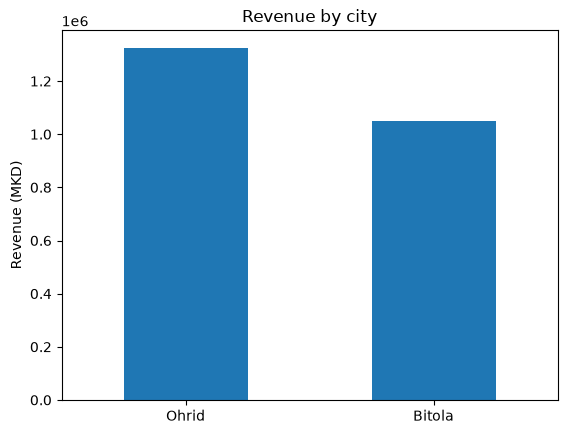

In [85]:
revenue_by_city = df.groupby("city")["revenue"].sum().sort_values(ascending=False)

chart = revenue_by_city.plot(kind = "bar", title = "Revenue by city", rot = 0)
chart.set_ylabel("Revenue (MKD)")
chart.set_xlabel("");

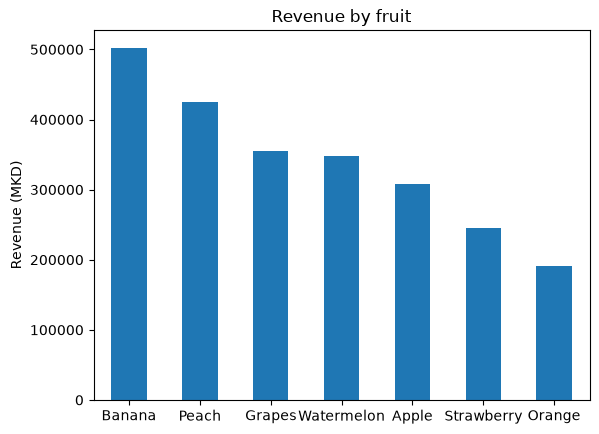

In [86]:
revenue_by_fruit = df.groupby("name")["revenue"].sum().sort_values(ascending=False)

chart = revenue_by_fruit.plot(kind="bar", title="Revenue by fruit", rot=0)
chart.set_ylabel("Revenue (MKD)")
chart.set_xlabel("");

In [87]:
monthly = df.pivot_table(
    index="month",
    columns="city",
    values="revenue",
    aggfunc="sum"
)
monthly


city,Bitola,Ohrid
month,,
7,346808.0,480447.0
8,363845.0,543563.0
9,338315.0,300788.0


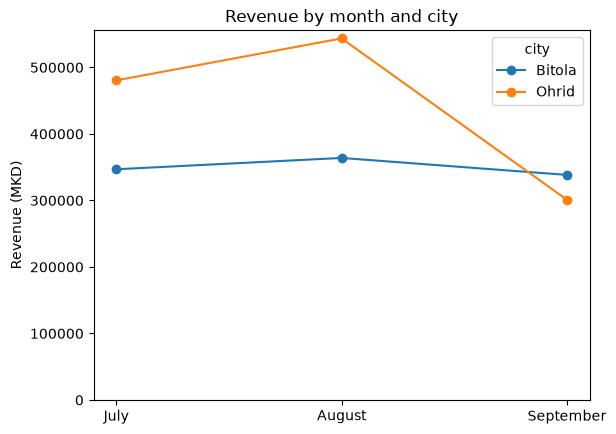

In [88]:
chart = monthly.plot(kind="line", title="Revenue by month and city", marker="o", rot=0)
chart.set_ylabel("Revenue (MKD)")
chart.set_xlabel("")
chart.set_xticks([7, 8, 9], ["July", "August", "September"])
chart.set_ylim(0);

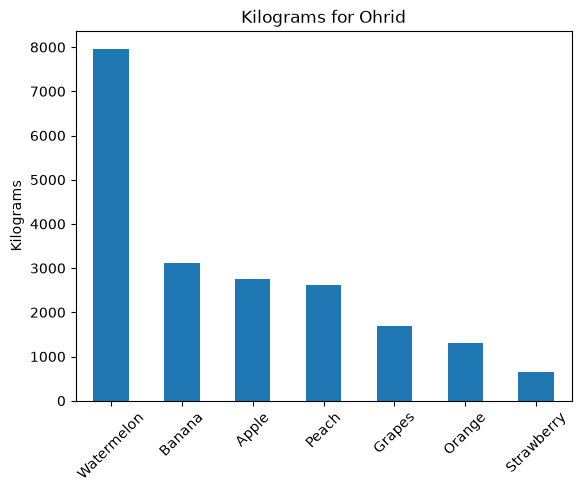

In [89]:
ohrid = df[df["city"] == "Ohrid"]
quantity_kg_per_ohrid = ohrid.groupby("name")["quantity_kg"].sum().sort_values(ascending=False)

chart = quantity_kg_per_ohrid.plot(kind = "bar", title = "Kilograms for Ohrid", rot=45)
chart.set_xlabel("")
chart.set_ylabel("Kilograms");


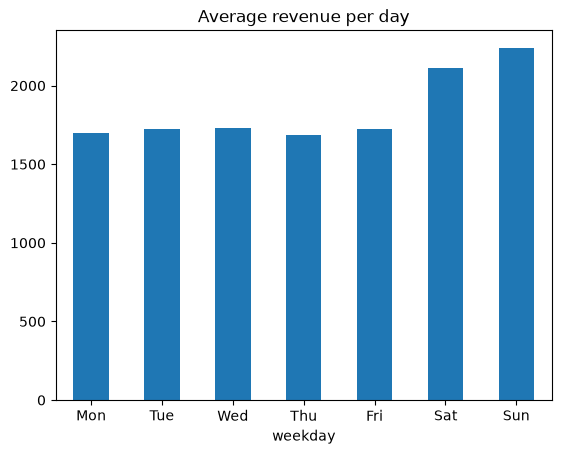

In [90]:
df["weekday"] = df["sale_date"].dt.dayofweek
df["is_weekend"] = df["weekday"] >= 5
df.head()


average_revenue = df.groupby("weekday")["revenue"].mean()

chart = average_revenue.plot(kind="bar", title = "Average revenue per day", rot=0)
chart.set_ylim(0)
chart.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]);


In [91]:
df.groupby("is_weekend")["revenue"].mean()

is_weekend
False    1712.085498
True     2175.271978
Name: revenue, dtype: float64

Text(0, 0.5, '')

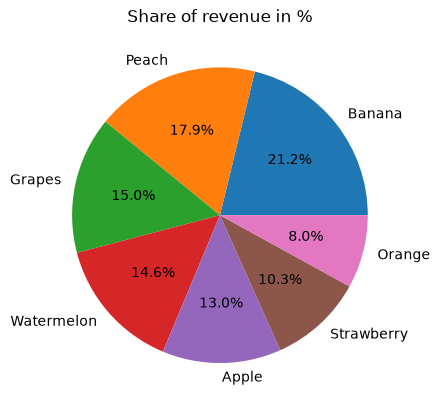

In [92]:
revenue_by_fruit = df.groupby("name")["revenue"].sum().sort_values(ascending=False)
total = df["revenue"].sum()
share = (revenue_by_fruit / total * 100).round(1)
share.head()

chart = share.plot(kind="pie", title = "Share of revenue in %", autopct="%.1f%%")
chart.set_ylabel("")

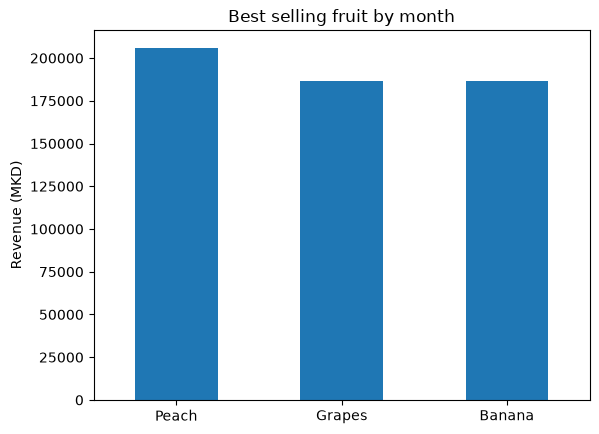

In [93]:
month_fruit = df.groupby(["month", "name"])["revenue"].sum().reset_index()
best_sell = month_fruit.sort_values("revenue", ascending=False).groupby("month").head(1)  
best_sell
chart = best_sell.plot(kind="bar", x="name", y="revenue", title="Best selling fruit by month", rot=0, legend=False)
chart.set_xlabel("")
chart.set_ylabel("Revenue (MKD)");


In [99]:
bitola = df[df["city"] == "Bitola"]
bitola.groupby("name")["quantity_kg"].mean().round(1).sort_values(ascending=True)


name
Strawberry     5.2
Orange        11.7
Grapes        16.7
Peach         20.2
Apple         25.8
Banana        26.7
Watermelon    64.6
Name: quantity_kg, dtype: float64

In [105]:
strawberry = df[df["name"] == "Strawberry"]
strawberry.groupby("city")["revenue"].sum()

city
Bitola    104522.0
Ohrid     141020.0
Name: revenue, dtype: float64

In [ ]:
## Conclusion
- Banana brought the most revenue (21.2% of total). Banana, Peach and Grapes together bring 54% of all revenue.
- Ohrid earned more than Bitola in July and August, but in September it fell below Bitola, because the summer tourists left.
- Weekend sales are about 27% higher than weekday sales.
- The best-selling fruit changed every month: Banana in July, Peach in August, Grapes in September.

**Recommendation:** from September, order fewer watermelons and peaches for Ohrid, and more grapes and apples.